# Customer Churn & Retention Analysis
## End-to-End Exploratory Data Analysis (EDA) using Python

**Objective:** Explore customer churn patterns and identify customer segments associated with churn. This notebook focuses on analytical thinking and business interpretation, not machine-learning model accuracy.

### Workflow
1. Load and inspect the dataset
2. Clean and validate the data
3. Frame business questions
4. Analyze patterns using statistics and visualizations
5. Summarize insights
6. Document limitations and assumptions

**Before running:** Download the Telco Customer Churn CSV and place it in `../data/`, or upload it when prompted.

## 1. Import libraries

In [6]:
import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the dataset

In [4]:
import os
import glob
import pandas as pd

possible_paths = [
    "../data/WA_Fn-UseC_-Telco-Customer-Churn.csv",
    "../data/Telco-Customer-Churn.csv",
    "data/WA_Fn-UseC_-Telco-Customer-Churn.csv",
    "data/Telco-Customer-Churn.csv",
]

DATA_PATH = next(
    (p for p in possible_paths if os.path.exists(p)),
    None
)

if DATA_PATH is None:
    csv_files = (
        glob.glob("../data/*.csv")
        + glob.glob("data/*.csv")
    )
    if csv_files:
        DATA_PATH = csv_files[0]

if DATA_PATH is None:
    raise FileNotFoundError(
        "CSV not found. Check that the CSV file is inside the data folder."
    )

df = pd.read_csv(DATA_PATH)

print("Loaded:", DATA_PATH)
print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

df.head()

Loaded: ../data/Telco-Customer-Churn.csv
Dataset loaded successfully.
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Task 1 — Initial inspection

In [5]:
print("Dataset shape (rows, columns):", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)

Dataset shape (rows, columns): (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


In [6]:
display(df.head())
display(df.sample(min(5, len(df)), random_state=42))
display(df.describe(include="all").T)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
185,1024-GUALD,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,24.80,24.8,Yes
2715,0484-JPBRU,Male,0,No,No,41,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Bank transfer (automatic),25.25,996.45,No
3825,3620-EHIMZ,Female,0,Yes,Yes,52,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.35,1031.7,No
1807,6910-HADCM,Female,0,No,No,1,Yes,No,Fiber optic,No,...,Yes,No,No,No,Month-to-month,No,Electronic check,76.35,76.35,Yes
132,8587-XYZSF,Male,0,No,No,67,Yes,No,DSL,No,...,No,Yes,No,No,Two year,No,Bank transfer (automatic),50.55,3260.1,No


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Initial observations — fill after checking output
- Number of records and columns: use the shape output above.
- Identify numeric, categorical and identifier columns from the data types.
- Check whether `Churn` is the target outcome column.
- Note any unusual values or inconsistent representations.

## 4. Task 2 — Data quality checks

In [7]:
print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

print("Exact duplicate rows:", df.duplicated().sum())

print("\nUnique values in key categorical columns (when present):")
for col in ["Churn", "Contract", "InternetService", "PaymentMethod", "gender"]:
    if col in df.columns:
        print(f"\n{col}:")
        print(df[col].value_counts(dropna=False))

Missing values by column:


,missing_count
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Exact duplicate rows: 0

Unique values in key categorical columns (when present):

Churn:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Contract:
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

InternetService:
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

PaymentMethod:
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

gender:
gender
Male      3555
Female    3488
Name: count, dtype: int64


In [8]:
# Work on a copy; retain the original DataFrame for reference.
clean_df = df.copy()

# Standardize column names by trimming accidental spaces only.
clean_df.columns = clean_df.columns.str.strip()

# Convert TotalCharges to numeric if present. Blank strings become NaN.
if "TotalCharges" in clean_df.columns:
    clean_df["TotalCharges"] = pd.to_numeric(clean_df["TotalCharges"], errors="coerce")

# Convert SeniorCitizen to a readable category for charts, while retaining the original numeric column.
if "SeniorCitizen" in clean_df.columns:
    clean_df["SeniorCitizenLabel"] = clean_df["SeniorCitizen"].map({0: "No", 1: "Yes"}).fillna("Unknown")

print("Missing values after type conversion:")
display(clean_df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

Missing values after type conversion:


,missing_count
TotalCharges,11
customerID,0
SeniorCitizen,0
Partner,0
Dependents,0
gender,0
tenure,0
PhoneService,0
InternetService,0
MultipleLines,0


### Cleaning decisions and justification
- `TotalCharges` may be stored as text despite representing a numeric amount; converting it enables numeric summaries. Unparseable/blank values become missing rather than being guessed.
- Missing values are inspected before deciding how to handle them. Avoid automatically deleting every row with a missing value.
- Duplicate rows are reported. Investigate them before removal because repeated records can sometimes be legitimate.
- Outliers are flagged for review; unusual values are not automatically deleted.

In [10]:
# Optional duplicate handling: only drop exact duplicates after confirming they are unintended.
# If you decide they are accidental duplicates, uncomment:
# clean_df = clean_df.drop_duplicates().copy()

# Numeric distribution and IQR outlier counts
import numpy as np
numeric_cols = clean_df.select_dtypes(include=np.number).columns.tolist()
outlier_summary = []
for col in numeric_cols:
    series = clean_df[col].dropna()
    if len(series) == 0:
        continue
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((series < lower) | (series > upper)).sum())
    outlier_summary.append({
        "column": col, "lower_IQR_bound": lower,
        "upper_IQR_bound": upper, "potential_outliers": count
    })
display(pd.DataFrame(outlier_summary))

,column,lower_IQR_bound,upper_IQR_bound,potential_outliers
0,SeniorCitizen,0.00000,0.00000,1142
1,tenure,-60.00000,124.00000,0
2,MonthlyCharges,-46.02500,171.37500,0
3,TotalCharges,-4688.48125,8884.66875,0


## 5. Task 3 — Business questions

These questions are designed around business decisions rather than programming techniques:

1. What proportion of customers have churned?
2. How does churn rate differ by contract type?
3. How does churn vary by internet service type?
4. Is churn rate associated with customer tenure?
5. How does churn differ across monthly-charge groups?
6. Does churn rate vary by payment method?
7. Is churn different for paperless-billing customers?
8. How does churn vary by senior-citizen status?
9. Is churn associated with having online security?
10. Is churn associated with having technical support?
11. How does churn differ by partner or dependent status?
12. Which numerical features are correlated with each other?

The dataset must contain the relevant columns for each question. The notebook checks column availability before running analyses.

## 6. Task 4 — Exploratory analysis

### 6.1 Overall churn

,customer_count
Churn,
No,5174
Yes,1869


Observed churn rate: 26.54%


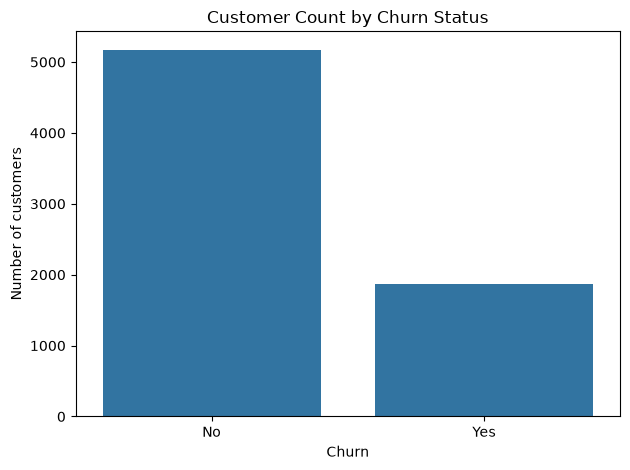

In [13]:
import seaborn as sns 
import matplotlib.pyplot as plt
if "Churn" in clean_df.columns:
    churn_counts = clean_df["Churn"].value_counts(dropna=False)
    display(churn_counts.to_frame("customer_count"))

    churn_rate = (clean_df["Churn"].astype(str).str.strip().str.lower() == "yes").mean() * 100
    print(f"Observed churn rate: {churn_rate:.2f}%")

    sns.countplot(data=clean_df, x="Churn", order=clean_df["Churn"].value_counts().index)
    plt.title("Customer Count by Churn Status")
    plt.xlabel("Churn")
    plt.ylabel("Number of customers")
    plt.tight_layout()
    plt.show()
else:
    print("The dataset has no 'Churn' column. Review the dataset and update the analysis.")

### 6.2 Churn by business categories

,churn_rate_percent
Contract,
Month-to-month,42.709677
One year,11.269518
Two year,2.831858


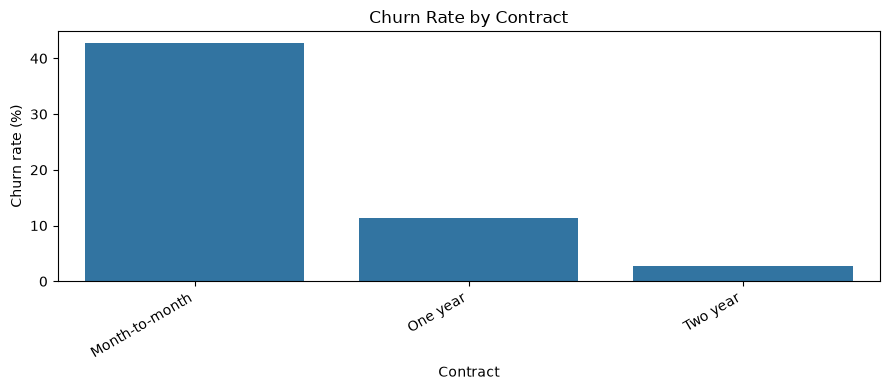

,churn_rate_percent
InternetService,
Fiber optic,41.892765
DSL,18.959108
No,7.404980


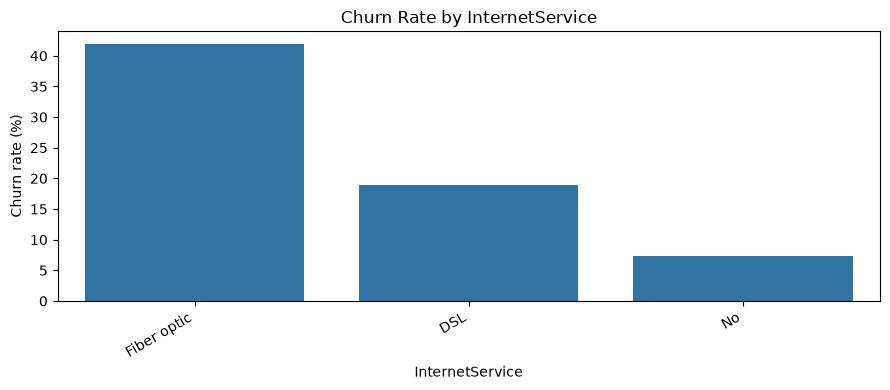

,churn_rate_percent
PaymentMethod,
Electronic check,45.285412
Mailed check,19.106700
Bank transfer (automatic),16.709845
Credit card (automatic),15.243101


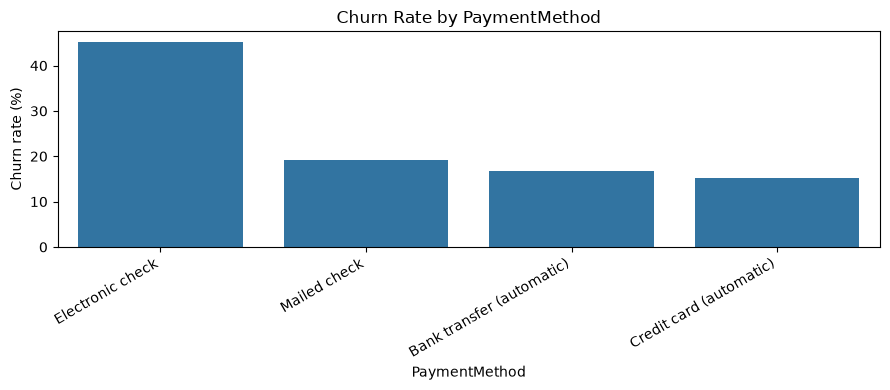

,churn_rate_percent
PaperlessBilling,
Yes,33.565092
No,16.330084


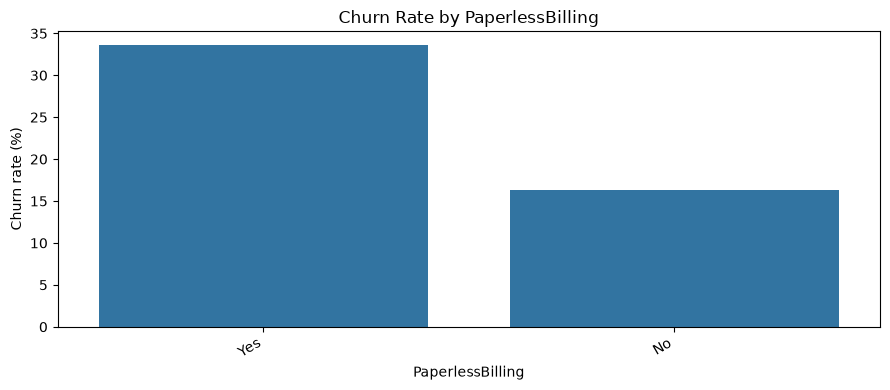

,churn_rate_percent
SeniorCitizenLabel,
Yes,41.681261
No,23.606168


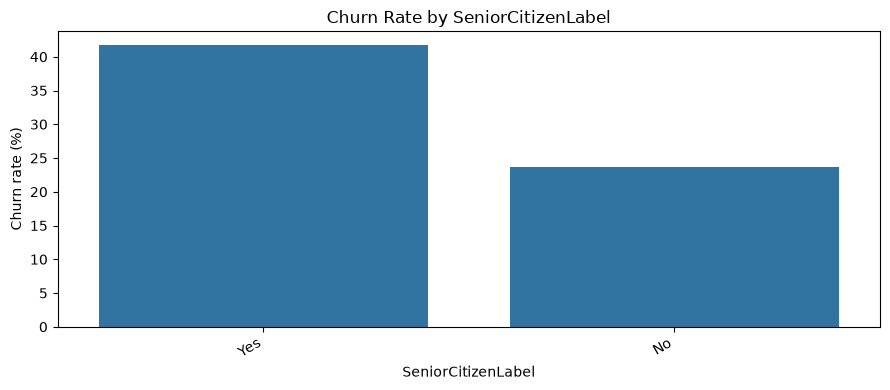

,churn_rate_percent
OnlineSecurity,
No,41.766724
Yes,14.611194
No internet service,7.404980


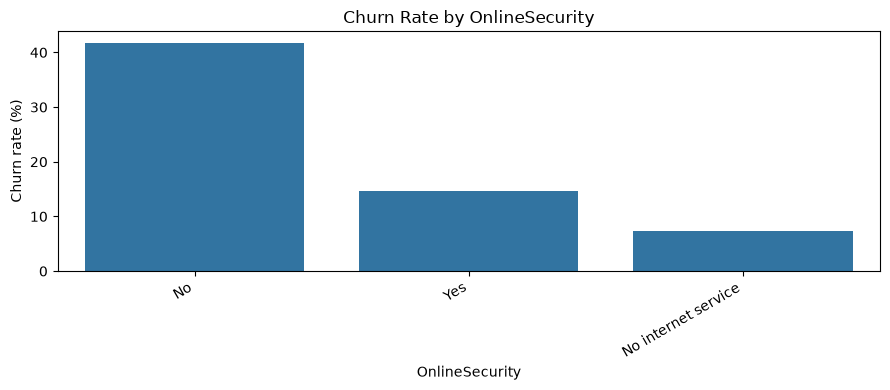

,churn_rate_percent
TechSupport,
No,41.635474
Yes,15.166341
No internet service,7.404980


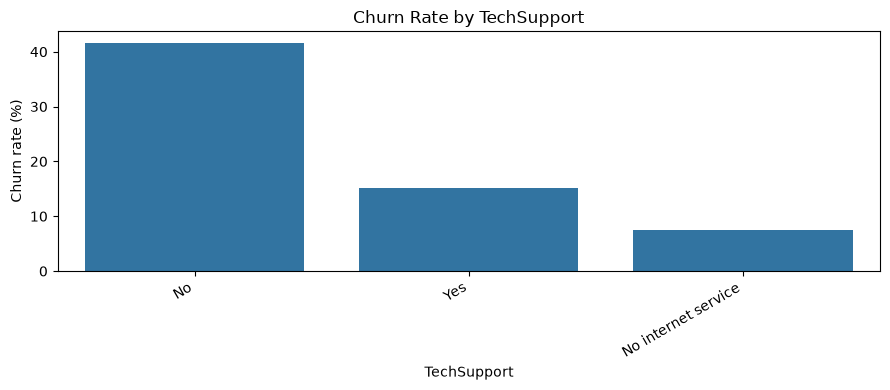

,churn_rate_percent
Partner,
No,32.957979
Yes,19.664903


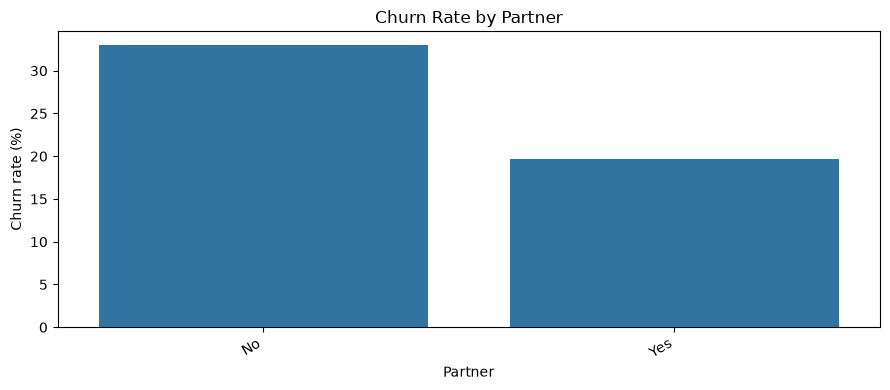

,churn_rate_percent
Dependents,
No,31.279140
Yes,15.450237


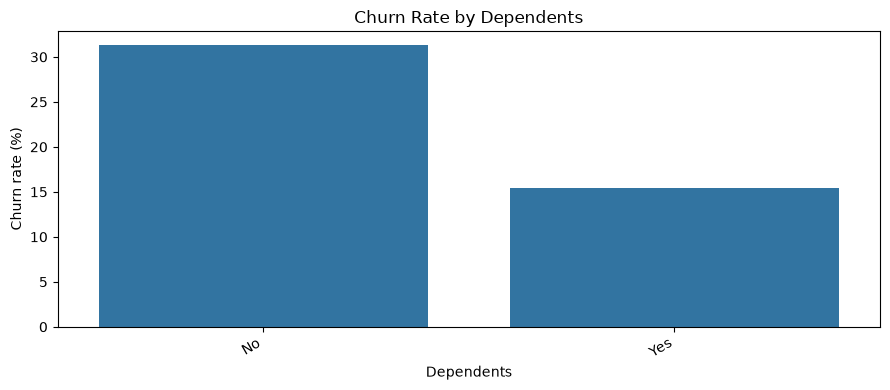

In [14]:
categorical_candidates = [
    "Contract", "InternetService", "PaymentMethod", "PaperlessBilling",
    "SeniorCitizenLabel", "OnlineSecurity", "TechSupport", "Partner", "Dependents"
]

def plot_churn_rate_by_category(data, column, outcome="Churn"):
    if column not in data.columns or outcome not in data.columns:
        print(f"Skipped {column}: required column not found.")
        return
    temp = data[[column, outcome]].dropna().copy()
    temp[outcome] = temp[outcome].astype(str).str.strip()
    temp["_churn_yes"] = temp[outcome].str.lower().eq("yes").astype(int)
    rates = (temp.groupby(column, dropna=False)["_churn_yes"].mean() * 100).sort_values(ascending=False)
    display(rates.rename("churn_rate_percent").to_frame())
    plt.figure(figsize=(9, 4))
    sns.barplot(x=rates.index.astype(str), y=rates.values)
    plt.title(f"Churn Rate by {column}")
    plt.xlabel(column)
    plt.ylabel("Churn rate (%)")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

for col in categorical_candidates:
    if col in clean_df.columns:
        plot_churn_rate_by_category(clean_df, col)

### 6.3 Numeric distributions

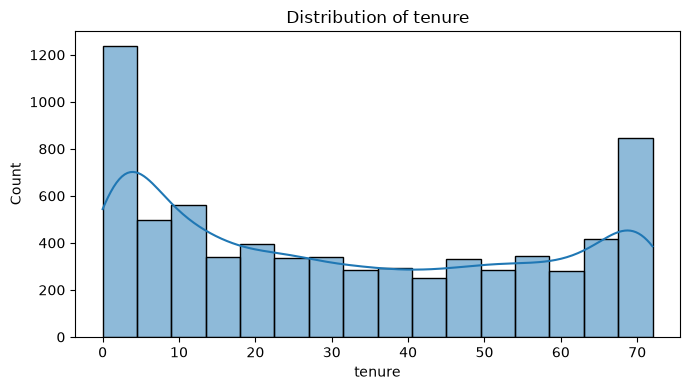

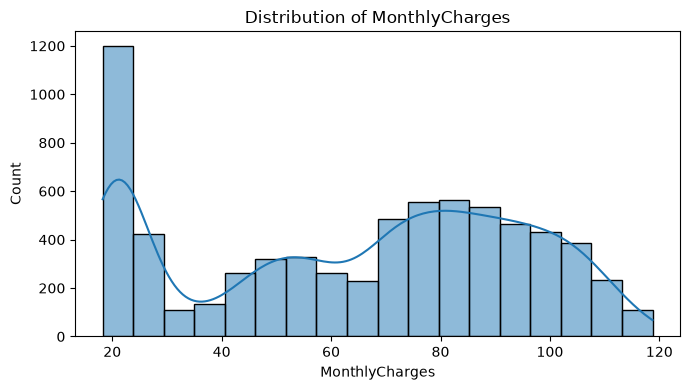

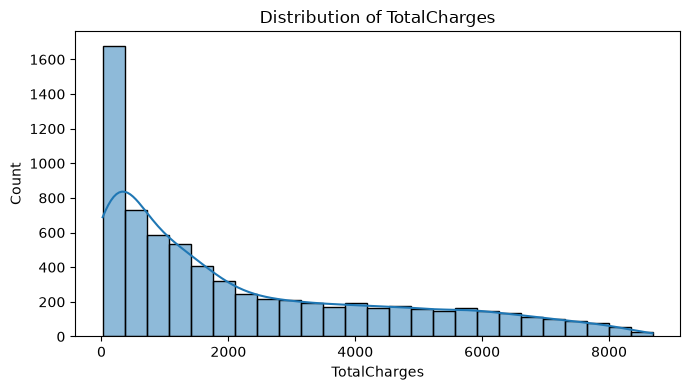

In [15]:
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    if col in clean_df.columns:
        plt.figure(figsize=(7, 4))
        sns.histplot(data=clean_df, x=col, kde=True)
        plt.title(f"Distribution of {col}")
        plt.tight_layout()
        plt.show()

### 6.4 Compare numeric features by churn

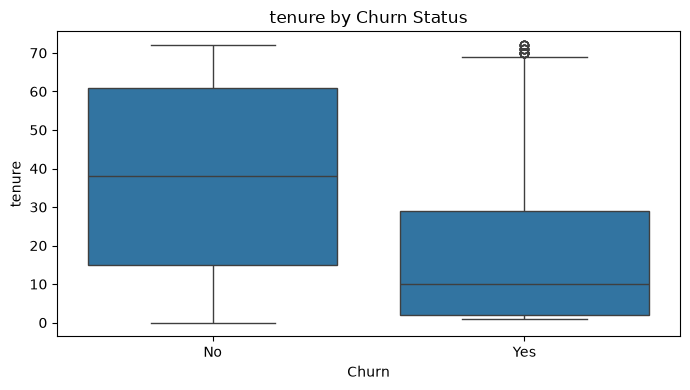

,count,mean,median,min,max
Churn,,,,,
No,5174,37.569965,38.0,0,72
Yes,1869,17.979133,10.0,1,72


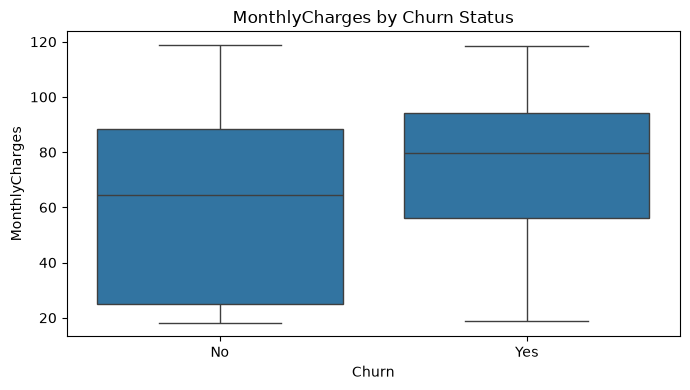

,count,mean,median,min,max
Churn,,,,,
No,5174,61.265124,64.425,18.25,118.75
Yes,1869,74.441332,79.650,18.85,118.35


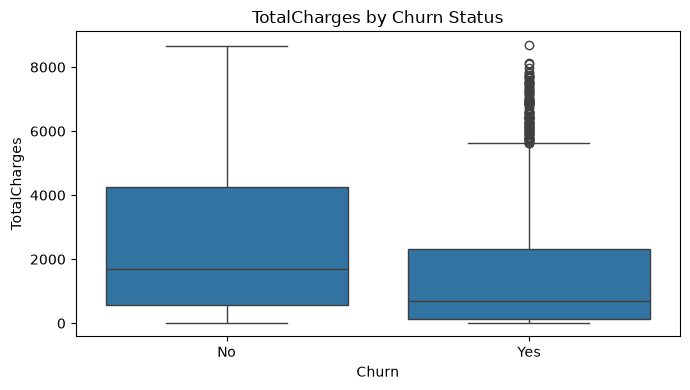

,count,mean,median,min,max
Churn,,,,,
No,5163,2555.344141,1683.60,18.80,8672.45
Yes,1869,1531.796094,703.55,18.85,8684.80


In [16]:
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    if col in clean_df.columns and "Churn" in clean_df.columns:
        plt.figure(figsize=(7, 4))
        sns.boxplot(data=clean_df, x="Churn", y=col)
        plt.title(f"{col} by Churn Status")
        plt.tight_layout()
        plt.show()

        display(clean_df.groupby("Churn")[col].agg(["count", "mean", "median", "min", "max"]))

### 6.5 Correlation among numeric variables

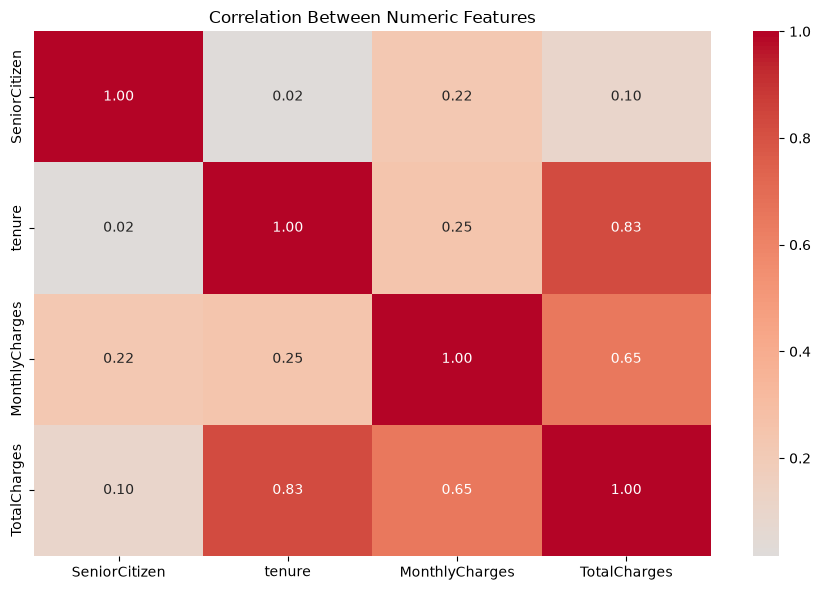

In [17]:
numeric_for_corr = clean_df.select_dtypes(include=np.number)
if numeric_for_corr.shape[1] >= 2:
    corr = numeric_for_corr.corr(numeric_only=True)
    plt.figure(figsize=(9, 6))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Correlation Between Numeric Features")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns to calculate a correlation matrix.")

## 7. Task 5 — Insights and business interpretation

Use the actual outputs and charts to complete this section. Do not invent findings.

For each insight, write:
- **Finding:** What did the analysis show? Include a count or percentage when useful.
- **Interpretation:** Why could this matter to the business?
- **Action to consider:** What could the business investigate or test next?

Example writing structure (replace with your actual results):
> Customers in [segment] had a churn rate of [X%], compared with [Y%] for [comparison segment]. This indicates an association between [feature] and churn in this dataset. The business could investigate the needs of this group and test a suitable retention approach.

Remember: an observed association does not prove causation.

## 8. Task 6 — Limitations and assumptions

Review and adapt these points to your analysis:
- The dataset is a sample and may not represent every telecom company or current customer population.
- The available columns may not capture all reasons customers leave.
- Missing or incorrectly recorded values can affect statistics and comparisons.
- IQR-based outlier flags identify values for review; they do not prove that a value is an error.
- Churn patterns are observational and do not establish cause and effect.
- Recommendations should be tested with additional evidence before making major business decisions.
- Any rows removed, values converted, or missing values handled should be documented with a reason.

## 9. Conclusion

In [18]:
# Helper: show a concise summary based on the data actually loaded.
if "Churn" in clean_df.columns:
    churn_norm = clean_df["Churn"].astype(str).str.strip().str.lower()
    print(f"Records analyzed: {len(clean_df):,}")
    print(f"Observed churn rate: {churn_norm.eq('yes').mean() * 100:.2f}%")
    if "Contract" in clean_df.columns:
        temp = clean_df.assign(_churn_yes=churn_norm.eq("yes").astype(int))
        contract_rates = temp.groupby("Contract")["_churn_yes"].mean().mul(100).sort_values(ascending=False)
        print("\nChurn rate by contract type (%):")
        display(contract_rates.to_frame("churn_rate_percent"))
else:
    print("Run the notebook after loading a compatible dataset, then summarize your actual findings here.")

Records analyzed: 7,043
Observed churn rate: 26.54%

Churn rate by contract type (%):


,churn_rate_percent
Contract,
Month-to-month,42.709677
One year,11.269518
Two year,2.831858


### Final conclusion — complete after reviewing all results
Summarize the 2–4 most important patterns, explain their business relevance, and state the next steps you recommend. Make sure every claim is supported by an output or visualization in this notebook.